# Paso 5 · Comparación estadística: DeLong, McNemar y bootstrap pareado

**Qué hace este notebook**
1. Une las puntuaciones del conjunto de prueba de scikit-learn y PySpark (mismas 269 062 filas, unidas por `id`).
2. Calcula AUC con IC 95 % y valida la implementación rápida de DeLong contra una versión ingenua y contra `roc_auc_score`.
3. **DeLong**: 6 comparaciones entre entornos (mismo modelo) y 15 pares entre modelos en cada entorno, con corrección de Holm y margen de relevancia práctica.
4. **McNemar** y **bootstrap pareado** (ΔAUC, ΔAUC-PR, ΔF1) para las 6 comparaciones entre entornos y para los 2 mejores modelos de cada entorno.
5. Tabla resumen de las tres pruebas, curvas ROC, tiempos y mapas de calor.

**Idea clave:** todas las puntuaciones están sobre las mismas observaciones de prueba, así que las comparaciones son **pareadas**. Por eso se usan pruebas que tienen en cuenta la correlación entre modelos.

## 1. Configuración

In [1]:
import os, time, itertools, warnings
import numpy as np, pandas as pd
from scipy.stats import rankdata, norm, chi2, binomtest
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, f1_score
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

RUTA = '/content/drive/MyDrive/ML_LendingClub'   # <- ajusta si tu carpeta se llama distinto
DIR_OUT = RUTA + '/resultados_pruebas'
os.makedirs(DIR_OUT, exist_ok=True)

SEMILLA = 42
B = 2000                 # réplicas bootstrap (el enunciado pide B >= 2000)
MARGEN = 0.005           # diferencia de AUC con relevancia práctica
ALFA = 0.05
MODELOS = ['NaiveBayes', 'LogisticRegression', 'DecisionTree', 'LinearSVC', 'GradientBoosting', 'RandomForest']
UMBRAL = {m: (0.0 if m == 'LinearSVC' else 0.5) for m in MODELOS}   # 0.5 para probabilidades, 0 para márgenes del SVM

Mounted at /content/drive


## 2. Carga y alineación de las puntuaciones

In [2]:
sk = pd.read_parquet(RUTA + '/scores_sklearn.parquet')
sp = pd.read_parquet(RUTA + '/scores_pyspark.parquet')
print('sklearn:', sk.shape, '| pyspark:', sp.shape)

sk['id'] = sk['id'].astype(str); sp['id'] = sp['id'].astype(str)
df = sk.merge(sp, on='id', suffixes=('_sk', '_sp'))
assert len(df) == len(sk) == len(sp), 'las particiones de prueba no coinciden'
assert (df['default_sk'] == df['default_sp']).all(), 'etiquetas distintas entre entornos'
y = df['default_sk'].values.astype(int)

S = {}   # puntuaciones: S[('sklearn', modelo)]
for m in MODELOS:
    S[('sklearn', m)] = df[m + '_sk'].values.astype(float)
    S[('pyspark', m)] = df[m + '_sp'].values.astype(float)
print('Filas de prueba:', len(y), '| tasa de default: %.3f %%' % (100 * y.mean()))

sklearn: (269062, 8) | pyspark: (269062, 8)
Filas de prueba: 269062 | tasa de default: 19.963 %


## 3. DeLong rápido (Sun & Xu, 2014)

La prueba de DeLong estima la covarianza entre AUC calculados sobre **las mismas observaciones**. La versión rápida usa rangos (`O(n log n)`) en vez de comparar todos los pares positivo-negativo (`O(m·n)`, imposible con ~54 000 positivos y ~215 000 negativos).

Calculamos de una vez la matriz de covarianza de los 12 AUC (6 modelos × 2 entornos). Cualquier contraste se obtiene como `Var(AUC_i − AUC_j) = S_ii + S_jj − 2·S_ij`.

In [3]:
def delong_cov(y, preds):
    """preds: matriz (k, n) de puntuaciones. Devuelve (AUCs, matriz de covarianza k x k)."""
    y = np.asarray(y).astype(bool)
    orden = np.argsort(~y, kind='stable')          # positivos primero
    P = preds[:, orden]
    m = int(y.sum()); n = P.shape[1] - m
    pos, neg = P[:, :m], P[:, m:]
    k = P.shape[0]
    tx = np.empty((k, m)); ty = np.empty((k, n)); tz = np.empty((k, m + n))
    for i in range(k):
        tx[i] = rankdata(pos[i]); ty[i] = rankdata(neg[i]); tz[i] = rankdata(P[i])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1.0) / (2.0 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    sx = np.atleast_2d(np.cov(v01)); sy = np.atleast_2d(np.cov(v10))
    return aucs, sx / m + sy / n

def delong_naive(y, preds):
    """Versión O(m*n) de referencia, solo para validar en muestras pequeñas."""
    y = np.asarray(y).astype(bool)
    k = preds.shape[0]; m = y.sum(); n = (~y).sum()
    V01 = np.zeros((k, m)); V10 = np.zeros((k, n)); aucs = np.zeros(k)
    for r in range(k):
        a, b = preds[r, y], preds[r, ~y]
        psi = (a[:, None] > b[None, :]) + 0.5 * (a[:, None] == b[None, :])
        V01[r] = psi.mean(axis=1); V10[r] = psi.mean(axis=0); aucs[r] = psi.mean()
    return aucs, np.atleast_2d(np.cov(V01)) / m + np.atleast_2d(np.cov(V10)) / n

### 3.1 Validación de la implementación

In [4]:
# (a) contra la versión ingenua en una submuestra (incluye empates, como en DecisionTree)
rng = np.random.default_rng(SEMILLA)
idx = rng.choice(len(y), 1200, replace=False)
sub = np.vstack([S[('sklearn', 'LogisticRegression')][idx],
                 np.round(S[('sklearn', 'DecisionTree')][idx], 2),
                 S[('pyspark', 'RandomForest')][idx]])
a1, c1 = delong_cov(y[idx], sub); a2, c2 = delong_naive(y[idx], sub)
print('Máx. dif. AUC (rápida vs ingenua):', np.abs(a1 - a2).max())
print('Máx. dif. covarianza            :', np.abs(c1 - c2).max())

# (b) AUC con el conjunto completo contra roc_auc_score
claves = [(e, m) for m in MODELOS for e in ('sklearn', 'pyspark')]
M = np.vstack([S[k] for k in claves])
t0 = time.time(); AUC, COV = delong_cov(y, M); print('DeLong 12 modelos, conjunto completo: %.1f s' % (time.time() - t0))
ref = np.array([roc_auc_score(y, S[k]) for k in claves])
print('Máx. dif. AUC vs roc_auc_score  :', np.abs(AUC - ref).max())
assert np.abs(a1 - a2).max() < 1e-10 and np.abs(c1 - c2).max() < 1e-12 and np.abs(AUC - ref).max() < 1e-10
IDX = {k: i for i, k in enumerate(claves)}

Máx. dif. AUC (rápida vs ingenua): 1.1102230246251565e-16
Máx. dif. covarianza            : 0.0
DeLong 12 modelos, conjunto completo: 1.0 s
Máx. dif. AUC vs roc_auc_score  : 1.1102230246251565e-16


### 3.2 AUC con IC 95 %

In [5]:
Z = norm.ppf(0.975)
def contraste(k1, k2):
    i, j = IDX[k1], IDX[k2]
    d = AUC[i] - AUC[j]
    var = COV[i, i] + COV[j, j] - 2 * COV[i, j]
    se = np.sqrt(max(var, 0.0))
    if se < 1e-12:
        z, p = 0.0, 1.0
    else:
        z = d / se; p = 2 * norm.sf(abs(z))
    return dict(AUC_A=AUC[i], AUC_B=AUC[j], dAUC=d, IC_inf=d - Z * se, IC_sup=d + Z * se, z=z, p=p)

def holm(p):
    p = np.asarray(p, float); k = len(p); orden = np.argsort(p)
    aj = np.empty(k); mx = 0.0
    for r, i in enumerate(orden):
        mx = max(mx, (k - r) * p[i]); aj[i] = min(1.0, mx)
    return aj

tabla_auc = pd.DataFrame([
    dict(entorno=e, modelo=m, AUC=AUC[IDX[(e, m)]],
         IC_inf=AUC[IDX[(e, m)]] - Z * np.sqrt(COV[IDX[(e, m)], IDX[(e, m)]]),
         IC_sup=AUC[IDX[(e, m)]] + Z * np.sqrt(COV[IDX[(e, m)], IDX[(e, m)]]))
    for e in ('sklearn', 'pyspark') for m in MODELOS])
tabla_auc.to_csv(DIR_OUT + '/auc_ic95.csv', index=False)
tabla_auc.round(4)

,entorno,modelo,AUC,IC_inf,IC_sup
0,sklearn,NaiveBayes,0.6293,0.6267,0.6320
1,sklearn,LogisticRegression,0.7096,0.7072,0.7120
2,sklearn,DecisionTree,0.7019,0.6995,0.7043
3,sklearn,LinearSVC,0.7092,0.7069,0.7116
4,sklearn,GradientBoosting,0.7179,0.7155,0.7202
5,sklearn,RandomForest,0.7143,0.7119,0.7166
6,pyspark,NaiveBayes,0.6298,0.6272,0.6325
7,pyspark,LogisticRegression,0.7096,0.7073,0.7120
8,pyspark,DecisionTree,0.7007,0.6983,0.7031
9,pyspark,LinearSVC,0.6066,0.6038,0.6094


### 3.3 DeLong entre entornos (mismo modelo): 6 comparaciones

`ΔAUC = AUC(sklearn) − AUC(PySpark)`. Se aplica Holm sobre la familia de 6 pruebas. Una diferencia es **estadísticamente significativa** si `p_Holm < 0.05` y **prácticamente relevante** si `|ΔAUC| ≥ 0.005`.

In [6]:
filas = []
for m in MODELOS:
    r = contraste(('sklearn', m), ('pyspark', m)); r['modelo'] = m; filas.append(r)
de_entornos = pd.DataFrame(filas)[['modelo', 'AUC_A', 'AUC_B', 'dAUC', 'IC_inf', 'IC_sup', 'z', 'p']]
de_entornos['p_holm'] = holm(de_entornos['p'])
de_entornos['signif'] = de_entornos['p_holm'] < ALFA
de_entornos['relevante'] = de_entornos['dAUC'].abs() >= MARGEN
de_entornos.to_csv(DIR_OUT + '/delong_entre_entornos.csv', index=False)
de_entornos.rename(columns={'AUC_A': 'AUC_sklearn', 'AUC_B': 'AUC_pyspark'}).round(4)

,modelo,AUC_sklearn,AUC_pyspark,dAUC,IC_inf,IC_sup,z,p,p_holm,signif,relevante
0,NaiveBayes,0.6293,0.6298,-0.0005,-0.0006,-0.0004,-11.7962,0.0000,0.0000,True,False
1,LogisticRegression,0.7096,0.7096,-0.0000,-0.0001,0.0000,-1.3950,0.1630,0.1630,False,False
2,DecisionTree,0.7019,0.7007,0.0012,0.0003,0.0021,2.6429,0.0082,0.0247,True,False
3,LinearSVC,0.7092,0.6066,0.1027,0.0998,0.1055,70.4934,0.0000,0.0000,True,True
4,GradientBoosting,0.7179,0.7174,0.0004,0.0000,0.0008,2.0720,0.0383,0.0765,False,False
5,RandomForest,0.7143,0.7131,0.0012,0.0008,0.0016,6.1735,0.0000,0.0000,True,False


### 3.4 DeLong entre modelos dentro de cada entorno: 15 pares por entorno

In [7]:
de_modelos = {}
for e in ('sklearn', 'pyspark'):
    filas = []
    for a, b in itertools.combinations(MODELOS, 2):
        r = contraste((e, a), (e, b)); r['A'] = a; r['B'] = b; filas.append(r)
    t = pd.DataFrame(filas)[['A', 'B', 'AUC_A', 'AUC_B', 'dAUC', 'IC_inf', 'IC_sup', 'z', 'p']]
    t['p_holm'] = holm(t['p'])
    t['signif'] = t['p_holm'] < ALFA
    t['relevante'] = t['dAUC'].abs() >= MARGEN
    de_modelos[e] = t
    t.to_csv(DIR_OUT + f'/delong_entre_modelos_{e}.csv', index=False)
    print(f'--- {e}: {int(t.signif.sum())}/15 significativos tras Holm, {int((t.signif & t.relevante).sum())}/15 también relevantes')
de_modelos['sklearn'].round(4)

--- sklearn: 15/15 significativos tras Holm, 12/15 también relevantes
--- pyspark: 15/15 significativos tras Holm, 13/15 también relevantes


,A,B,AUC_A,AUC_B,dAUC,IC_inf,IC_sup,z,p,p_holm,signif,relevante
0,NaiveBayes,LogisticRegression,0.6293,0.7096,-0.0803,-0.0826,-0.0779,-67.8034,0.0000,0.0000,True,True
1,NaiveBayes,DecisionTree,0.6293,0.7019,-0.0726,-0.0753,-0.0698,-51.5022,0.0000,0.0000,True,True
2,NaiveBayes,LinearSVC,0.6293,0.7092,-0.0799,-0.0822,-0.0776,-66.9085,0.0000,0.0000,True,True
3,NaiveBayes,GradientBoosting,0.6293,0.7179,-0.0885,-0.0911,-0.0860,-68.0765,0.0000,0.0000,True,True
4,NaiveBayes,RandomForest,0.6293,0.7143,-0.0849,-0.0875,-0.0823,-63.8094,0.0000,0.0000,True,True
5,LogisticRegression,DecisionTree,0.7096,0.7019,0.0077,0.0065,0.0089,12.2990,0.0000,0.0000,True,True
6,LogisticRegression,LinearSVC,0.7096,0.7092,0.0004,0.0001,0.0007,2.3114,0.0208,0.0208,True,False
7,LogisticRegression,GradientBoosting,0.7096,0.7179,-0.0083,-0.0091,-0.0074,-20.1774,0.0000,0.0000,True,True
8,LogisticRegression,RandomForest,0.7096,0.7143,-0.0047,-0.0055,-0.0038,-10.9827,0.0000,0.0000,True,False
9,DecisionTree,LinearSVC,0.7019,0.7092,-0.0073,-0.0085,-0.0061,-12.1200,0.0000,0.0000,True,True


In [8]:
de_modelos['pyspark'].round(4)

,A,B,AUC_A,AUC_B,dAUC,IC_inf,IC_sup,z,p,p_holm,signif,relevante
0,NaiveBayes,LogisticRegression,0.6298,0.7096,-0.0798,-0.0821,-0.0775,-67.5790,0.0,0.0,True,True
1,NaiveBayes,DecisionTree,0.6298,0.7007,-0.0709,-0.0737,-0.0681,-50.3323,0.0,0.0,True,True
2,NaiveBayes,LinearSVC,0.6298,0.6066,0.0232,0.0199,0.0266,13.6392,0.0,0.0,True,True
3,NaiveBayes,GradientBoosting,0.6298,0.7174,-0.0876,-0.0901,-0.0851,-67.5787,0.0,0.0,True,True
4,NaiveBayes,RandomForest,0.6298,0.7131,-0.0832,-0.0858,-0.0806,-62.5093,0.0,0.0,True,True
5,LogisticRegression,DecisionTree,0.7096,0.7007,0.0089,0.0077,0.0101,14.7194,0.0,0.0,True,True
6,LogisticRegression,LinearSVC,0.7096,0.6066,0.1030,0.1002,0.1059,69.9154,0.0,0.0,True,True
7,LogisticRegression,GradientBoosting,0.7096,0.7174,-0.0078,-0.0086,-0.0069,-17.9529,0.0,0.0,True,True
8,LogisticRegression,RandomForest,0.7096,0.7131,-0.0034,-0.0043,-0.0026,-8.0478,0.0,0.0,True,False
9,DecisionTree,LinearSVC,0.7007,0.6066,0.0942,0.0912,0.0971,62.1910,0.0,0.0,True,True


### 3.5 Mapas de calor (ΔAUC y p ajustado de Holm)

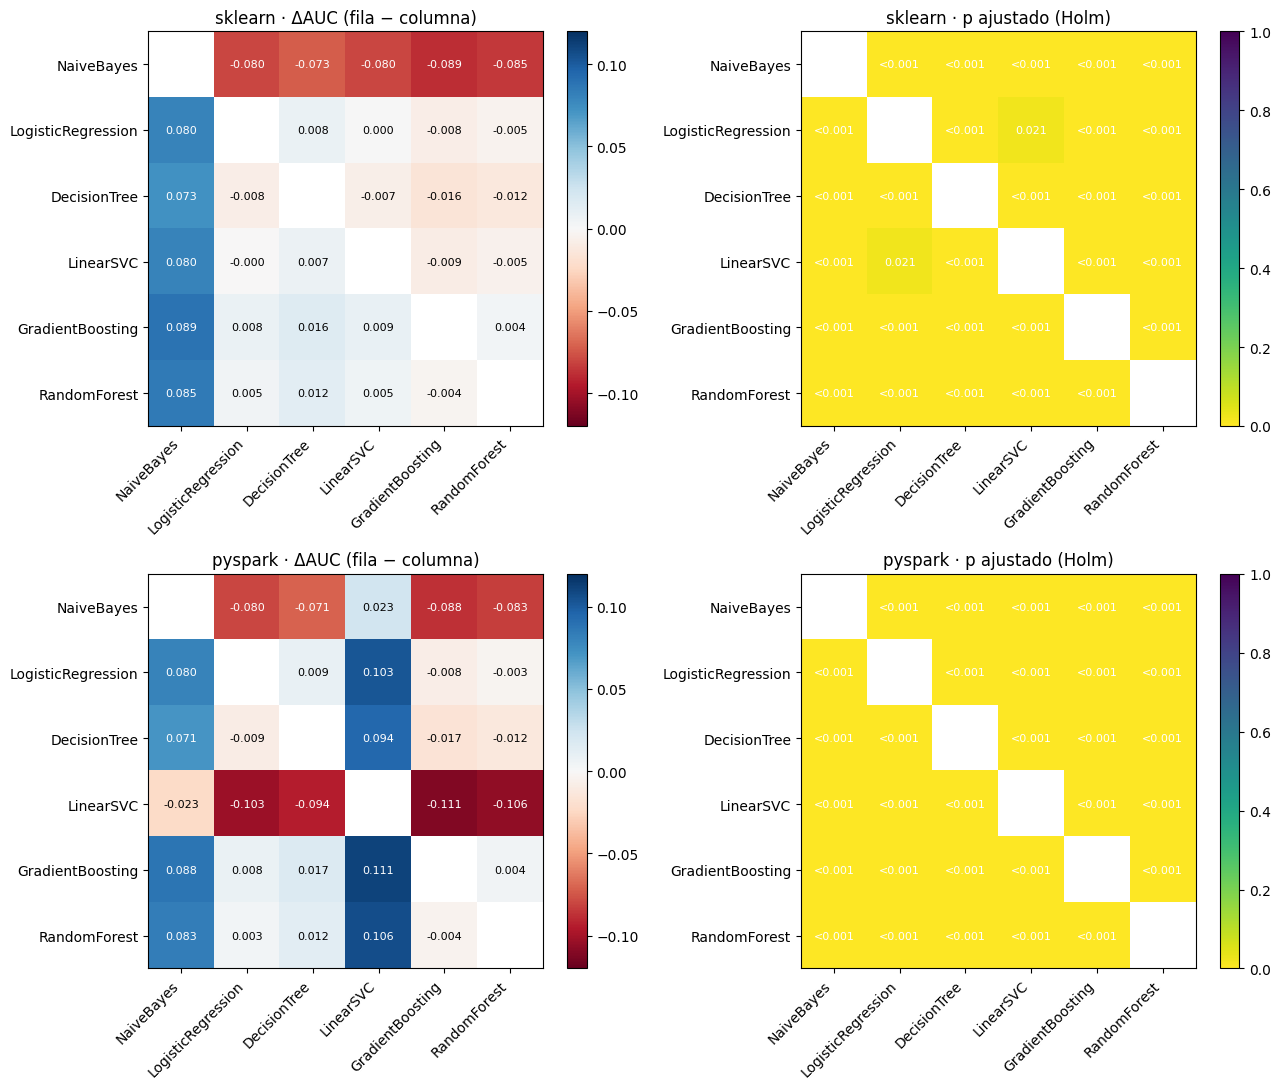

In [9]:
def mat(e, col):
    M_ = pd.DataFrame(np.nan, index=MODELOS, columns=MODELOS)
    for _, r in de_modelos[e].iterrows():
        v = r[col]
        M_.loc[r['A'], r['B']] = v
        M_.loc[r['B'], r['A']] = -v if col == 'dAUC' else v
    return M_

fig, ax = plt.subplots(2, 2, figsize=(13, 11))
for f, e in enumerate(('sklearn', 'pyspark')):
    for c, (col, titulo, cmap) in enumerate((('dAUC', 'ΔAUC (fila − columna)', 'RdBu'), ('p_holm', 'p ajustado (Holm)', 'viridis_r'))):
        A = mat(e, col); a = ax[f, c]
        im = a.imshow(A.values.astype(float), cmap=cmap,
                      vmin=(-0.12 if col == 'dAUC' else 0), vmax=(0.12 if col == 'dAUC' else 1))
        a.set_xticks(range(6)); a.set_xticklabels(MODELOS, rotation=45, ha='right'); a.set_yticks(range(6)); a.set_yticklabels(MODELOS)
        for i in range(6):
            for j in range(6):
                v = A.values[i, j]
                if not np.isnan(v):
                    a.text(j, i, f'{v:.3f}' if col == 'dAUC' else ('<0.001' if v < 0.001 else f'{v:.3f}'), ha='center', va='center', fontsize=8,
                           color='black' if (col == 'dAUC' and abs(v) < 0.07) or (col != 'dAUC' and v > 0.5) else 'white')
        a.set_title(f'{e} · {titulo}'); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.savefig(DIR_OUT + '/heatmaps_delong.png', dpi=150); plt.show()

## 4. McNemar y bootstrap pareado

Las predicciones de clase usan el umbral **0.5** sobre probabilidades y **0** sobre el margen del SVM. Con la tasa de default de ~20 %, un umbral de 0.5 produce pocos positivos: las métricas de clase (F1, McNemar) son por eso mucho más bajas que el AUC. Es una limitación que se discute en el informe.

**Qué prueban:**
- *McNemar*: si dos clasificadores tienen distinta tasa de error sobre las mismas observaciones (solo cuentan los casos discordantes `b` y `c`).
- *Bootstrap pareado*: se remuestrean las observaciones de prueba con reemplazo (**la misma remuestra para ambos modelos**), se recalcula ΔAUC, ΔAUC-PR y ΔF1, y se toma el IC percentil 95 %. El p-valor es `2·min(P(Δ≤0), P(Δ≥0))`.

In [10]:
PRED = {k: (S[k] >= UMBRAL[k[1]]).astype(int) for k in claves}

def mcnemar(k1, k2):
    ok1 = PRED[k1] == y; ok2 = PRED[k2] == y
    b = int((ok1 & ~ok2).sum()); c = int((~ok1 & ok2).sum())
    if b + c == 0:
        return dict(b=b, c=c, estadistico=0.0, p=1.0, prueba='sin discordantes')
    if b + c < 25:
        return dict(b=b, c=c, estadistico=float(min(b, c)), p=float(binomtest(min(b, c), b + c, 0.5).pvalue), prueba='exacta')
    est = (abs(b - c) - 1) ** 2 / (b + c)
    return dict(b=b, c=c, estadistico=float(est), p=float(chi2.sf(est, 1)), prueba='chi2 con corrección')

class Boot:
    """Métricas ponderadas por conteos de remuestreo. Ordena una sola vez cada modelo (O(n) por réplica)."""
    def __init__(self, y, S, PRED, claves):
        self.y = y.astype(float); self.n = len(y)
        self.g = {}
        for k in claves:
            u, inv = np.unique(S[k], return_inverse=True)
            self.g[k] = (len(u), inv)
        self.PRED = PRED
    def metricas(self, k, w):
        G, inv = self.g[k]
        wy = w * self.y; wn = w - wy
        pos = np.bincount(inv, weights=wy, minlength=G); neg = np.bincount(inv, weights=wn, minlength=G)
        P, N = pos.sum(), neg.sum()
        auc = (pos * (np.cumsum(neg) - neg + 0.5 * neg)).sum() / (P * N)
        pd_, nd_ = pos[::-1], neg[::-1]
        tp = np.cumsum(pd_); fp = np.cumsum(nd_)
        tot = tp + fp
        prec = np.divide(tp, tot, out=np.zeros_like(tp), where=tot > 0)
        ap = (pd_ / P * prec).sum()
        pr = self.PRED[k]
        TP = (wy * pr).sum(); FP = (wn * pr).sum(); FN = (wy * (1 - pr)).sum()
        f1 = 2 * TP / (2 * TP + FP + FN) if TP > 0 else 0.0
        return auc, ap, f1

def remuestreos(claves_necesarias, B, semilla):
    bt = Boot(y, S, PRED, claves_necesarias)
    rng = np.random.default_rng(semilla)
    out = {k: np.zeros((B, 3)) for k in claves_necesarias}
    n = len(y)
    for b in range(B):
        w = np.bincount(rng.integers(0, n, n), minlength=n).astype(float)   # misma remuestra para todos los modelos
        for k in claves_necesarias:
            out[k][b] = bt.metricas(k, w)
    return out

### 4.1 Familias de comparaciones

In [11]:
# Familia 1: 6 comparaciones entre entornos (mismo modelo)
fam_entornos = [(('sklearn', m), ('pyspark', m), f'{m}: sklearn vs PySpark') for m in MODELOS]

# Familia 2: los 2 mejores modelos por AUC en cada entorno
fam_top2 = []
for e in ('sklearn', 'pyspark'):
    top = sorted(MODELOS, key=lambda m: -AUC[IDX[(e, m)]])[:2]
    print(f'Top-2 {e}:', top, [round(AUC[IDX[(e, m)]], 4) for m in top])
    fam_top2.append(((e, top[0]), (e, top[1]), f'{e}: {top[0]} vs {top[1]}'))

necesarias = sorted({k for f in (fam_entornos + fam_top2) for k in f[:2]})
t0 = time.time()
BOOT = remuestreos(necesarias, B, SEMILLA)
print('Bootstrap (B=%d, %d modelos): %.1f min' % (B, len(necesarias), (time.time() - t0) / 60))

Top-2 sklearn: ['GradientBoosting', 'RandomForest'] [np.float64(0.7179), np.float64(0.7143)]
Top-2 pyspark: ['GradientBoosting', 'RandomForest'] [np.float64(0.7174), np.float64(0.7131)]
Bootstrap (B=2000, 12 modelos): 3.0 min


In [12]:
def evaluar(familia, nombre_familia):
    filas = []
    for k1, k2, etiqueta in familia:
        mc = mcnemar(k1, k2)
        d = BOOT[k1] - BOOT[k2]                      # (B, 3): AUC, AUC-PR, F1
        f = dict(familia=nombre_familia, comparacion=etiqueta,
                 McNemar_b=mc['b'], McNemar_c=mc['c'], McNemar_p=mc['p'], McNemar_prueba=mc['prueba'])
        for j, nm in enumerate(('AUC', 'AUCPR', 'F1')):
            obs = {0: roc_auc_score(y, S[k1]) - roc_auc_score(y, S[k2]),
                   1: average_precision_score(y, S[k1]) - average_precision_score(y, S[k2]),
                   2: f1_score(y, PRED[k1]) - f1_score(y, PRED[k2])}[j]
            f[f'd{nm}'] = obs
            f[f'd{nm}_IC_inf'], f[f'd{nm}_IC_sup'] = np.percentile(d[:, j], [2.5, 97.5])
            f[f'd{nm}_p'] = min(1.0, 2 * min((d[:, j] <= 0).mean(), (d[:, j] >= 0).mean()) + 1.0 / (B + 1))
        c = contraste(k1, k2); f['DeLong_dAUC'] = c['dAUC']; f['DeLong_p'] = c['p']
        filas.append(f)
    t = pd.DataFrame(filas)
    t['McNemar_p_holm'] = holm(t['McNemar_p'])
    for nm in ('AUC', 'AUCPR', 'F1'):
        t[f'd{nm}_p_holm'] = holm(t[f'd{nm}_p'])
    t['DeLong_p_holm'] = holm(t['DeLong_p'])
    return t

res_entornos = evaluar(fam_entornos, 'entre entornos')
res_top2 = evaluar(fam_top2, 'top-2 por entorno')
res_entornos.to_csv(DIR_OUT + '/pruebas_entre_entornos.csv', index=False)
res_top2.to_csv(DIR_OUT + '/pruebas_top2.csv', index=False)
res_entornos.round(4)

,familia,comparacion,McNemar_b,McNemar_c,McNemar_p,McNemar_prueba,dAUC,dAUC_IC_inf,dAUC_IC_sup,dAUC_p,...,dF1_IC_inf,dF1_IC_sup,dF1_p,DeLong_dAUC,DeLong_p,McNemar_p_holm,dAUC_p_holm,dAUCPR_p_holm,dF1_p_holm,DeLong_p_holm
0,entre entornos,NaiveBayes: sklearn vs PySpark,2303,918,0.0000,chi2 con corrección,-0.0005,-0.0006,-0.0004,0.0005,...,-0.0004,0.0005,0.8735,-0.0005,0.0000,0.0000,0.0030,0.0030,1.0000,0.0000
1,entre entornos,LogisticRegression: sklearn vs PySpark,65,52,0.2673,chi2 con corrección,-0.0000,-0.0000,0.0000,0.1785,...,-0.0001,0.0007,0.1095,-0.0000,0.1630,0.8018,0.1785,0.1395,0.3285,0.1630
2,entre entornos,DecisionTree: sklearn vs PySpark,2809,2982,0.0238,chi2 con corrección,0.0012,0.0003,0.0021,0.0055,...,-0.0041,0.0023,0.6085,0.0012,0.0082,0.0952,0.0165,0.3585,1.0000,0.0247
3,entre entornos,LinearSVC: sklearn vs PySpark,1966,1610,0.0000,chi2 con corrección,0.1027,0.0998,0.1056,0.0005,...,0.0658,0.0714,0.0005,0.1027,0.0000,0.0000,0.0030,0.0030,0.0030,0.0000
4,entre entornos,GradientBoosting: sklearn vs PySpark,1571,1533,0.5066,chi2 con corrección,0.0004,0.0000,0.0008,0.0355,...,-0.0273,-0.0228,0.0005,0.0004,0.0383,1.0000,0.0710,0.1710,0.0030,0.0765
5,entre entornos,RandomForest: sklearn vs PySpark,437,423,0.6576,chi2 con corrección,0.0012,0.0008,0.0016,0.0005,...,0.0029,0.0059,0.0005,0.0012,0.0000,1.0000,0.0030,0.0030,0.0030,0.0000


In [13]:
res_top2.round(4)

,familia,comparacion,McNemar_b,McNemar_c,McNemar_p,McNemar_prueba,dAUC,dAUC_IC_inf,dAUC_IC_sup,dAUC_p,...,dF1_IC_inf,dF1_IC_sup,dF1_p,DeLong_dAUC,DeLong_p,McNemar_p_holm,dAUC_p_holm,dAUCPR_p_holm,dF1_p_holm,DeLong_p_holm
0,top-2 por entorno,sklearn: GradientBoosting vs RandomForest,2384,1942,0.0,chi2 con corrección,0.0036,0.0030,0.0042,0.0005,...,0.0723,0.0782,0.0005,0.0036,0.0,0.0,0.001,0.001,0.001,0.0
1,top-2 por entorno,pyspark: GradientBoosting vs RandomForest,3376,2958,0.0,chi2 con corrección,0.0044,0.0037,0.0050,0.0005,...,0.1011,0.1080,0.0005,0.0044,0.0,0.0,0.001,0.001,0.001,0.0


**Nota sobre Holm:** en esta tabla `DeLong_p_holm` se corrige dentro de cada familia de 6 y de 2 comparaciones. La corrección sobre las 15 comparaciones de modelos está en la sección 3.4.

## 5. Tabla resumen de las tres pruebas

In [14]:
resumen = pd.concat([res_entornos, res_top2], ignore_index=True)
def fmt_p(p): return '<0.001' if p < 0.001 else f'{p:.3f}'
tabla = pd.DataFrame({
    'Familia': resumen['familia'], 'Comparación': resumen['comparacion'],
    'ΔAUC (DeLong)': resumen['DeLong_dAUC'].round(4), 'p Holm DeLong': resumen['DeLong_p_holm'].map(fmt_p),
    'McNemar b/c': resumen['McNemar_b'].astype(str) + '/' + resumen['McNemar_c'].astype(str),
    'p Holm McNemar': resumen['McNemar_p_holm'].map(fmt_p),
    'ΔAUC boot [IC95]': [f'{a:.4f} [{b:.4f}, {c:.4f}]' for a, b, c in zip(resumen.dAUC, resumen.dAUC_IC_inf, resumen.dAUC_IC_sup)],
    'p Holm boot AUC': resumen['dAUC_p_holm'].map(fmt_p),
    'ΔAUC-PR boot [IC95]': [f'{a:.4f} [{b:.4f}, {c:.4f}]' for a, b, c in zip(resumen.dAUCPR, resumen.dAUCPR_IC_inf, resumen.dAUCPR_IC_sup)],
    'ΔF1 boot [IC95]': [f'{a:.4f} [{b:.4f}, {c:.4f}]' for a, b, c in zip(resumen.dF1, resumen.dF1_IC_inf, resumen.dF1_IC_sup)],
    'Relevante (|ΔAUC|≥%.3f)' % MARGEN: np.where(resumen['DeLong_dAUC'].abs() >= MARGEN, 'sí', 'no'),
})
tabla.to_csv(DIR_OUT + '/resumen_tres_pruebas.csv', index=False)
tabla

,Familia,Comparación,ΔAUC (DeLong),p Holm DeLong,McNemar b/c,p Holm McNemar,ΔAUC boot [IC95],p Holm boot AUC,ΔAUC-PR boot [IC95],ΔF1 boot [IC95],Relevante (|ΔAUC|≥0.005)
0,entre entornos,NaiveBayes: sklearn vs PySpark,-0.0005,<0.001,2303/918,<0.001,"-0.0005 [-0.0006, -0.0004]",0.003,"-0.0008 [-0.0009, -0.0007]","0.0000 [-0.0004, 0.0005]",no
1,entre entornos,LogisticRegression: sklearn vs PySpark,-0.0000,0.163,65/52,0.802,"-0.0000 [-0.0000, 0.0000]",0.178,"-0.0000 [-0.0001, -0.0000]","0.0003 [-0.0001, 0.0007]",no
2,entre entornos,DecisionTree: sklearn vs PySpark,0.0012,0.025,2809/2982,0.095,"0.0012 [0.0003, 0.0021]",0.016,"0.0008 [-0.0010, 0.0027]","-0.0009 [-0.0041, 0.0023]",no
3,entre entornos,LinearSVC: sklearn vs PySpark,0.1027,<0.001,1966/1610,<0.001,"0.1027 [0.0998, 0.1056]",0.003,"0.0785 [0.0755, 0.0813]","0.0686 [0.0658, 0.0714]",sí
4,entre entornos,GradientBoosting: sklearn vs PySpark,0.0004,0.077,1571/1533,1.000,"0.0004 [0.0000, 0.0008]",0.071,"0.0008 [-0.0001, 0.0017]","-0.0250 [-0.0273, -0.0228]",no
5,entre entornos,RandomForest: sklearn vs PySpark,0.0012,<0.001,437/423,1.000,"0.0012 [0.0008, 0.0016]",0.003,"0.0018 [0.0011, 0.0025]","0.0044 [0.0029, 0.0059]",no
6,top-2 por entorno,sklearn: GradientBoosting vs RandomForest,0.0036,<0.001,2384/1942,<0.001,"0.0036 [0.0030, 0.0042]",<0.001,"0.0052 [0.0041, 0.0062]","0.0752 [0.0723, 0.0782]",no
7,top-2 por entorno,pyspark: GradientBoosting vs RandomForest,0.0044,<0.001,3376/2958,<0.001,"0.0044 [0.0037, 0.0050]",<0.001,"0.0061 [0.0048, 0.0075]","0.1047 [0.1011, 0.1080]",no


## 6. Curvas ROC, tiempos y comparación de entornos

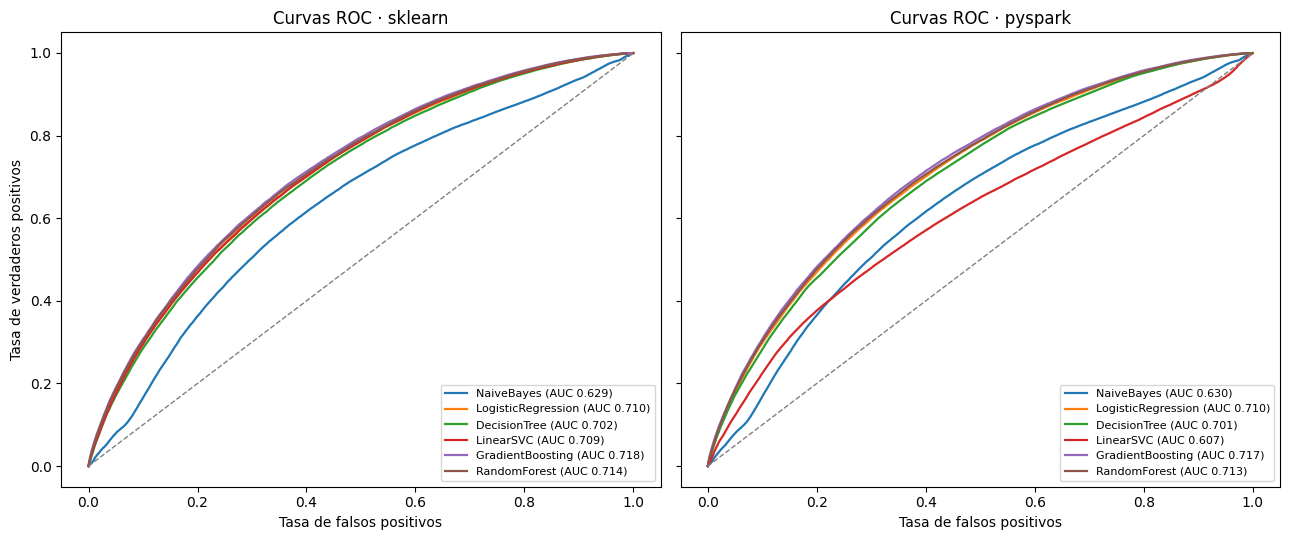

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
colores = plt.get_cmap('tab10')
for a, e in zip(ax, ('sklearn', 'pyspark')):
    for i, m in enumerate(MODELOS):
        fpr, tpr, _ = roc_curve(y, S[(e, m)])
        paso = max(1, len(fpr) // 800)
        a.plot(fpr[::paso], tpr[::paso], lw=1.6, color=colores(i), label=f'{m} (AUC {AUC[IDX[(e, m)]]:.3f})')
    a.plot([0, 1], [0, 1], '--', color='gray', lw=1)
    a.set_title(f'Curvas ROC · {e}'); a.set_xlabel('Tasa de falsos positivos'); a.legend(loc='lower right', fontsize=8)
ax[0].set_ylabel('Tasa de verdaderos positivos')
plt.tight_layout(); plt.savefig(DIR_OUT + '/roc_por_entorno.png', dpi=150); plt.show()

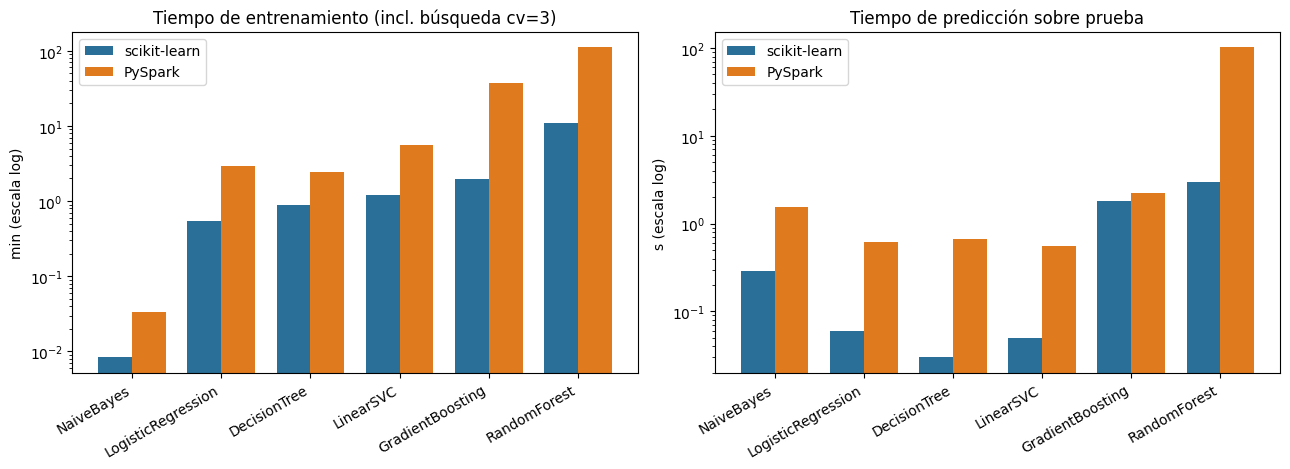

,modelo,sklearn_entren_min,pyspark_entren_min,sklearn_pred_s,pyspark_pred_s,razon_spark/sklearn
0,NaiveBayes,0.01,0.03,0.29,1.56,4.00
1,LogisticRegression,0.55,2.92,0.06,0.62,5.32
2,DecisionTree,0.88,2.44,0.03,0.67,2.76
3,LinearSVC,1.20,5.56,0.05,0.56,4.64
4,GradientBoosting,1.96,36.92,1.79,2.26,18.87
5,RandomForest,10.77,111.05,3.01,101.75,10.31


In [16]:
rs = pd.read_csv(RUTA + '/resultados_sklearn.csv'); rp = pd.read_csv(RUTA + '/resultados_pyspark.csv')
tiempos = pd.DataFrame({'modelo': MODELOS})
tiempos['sklearn_entren_min'] = [rs.set_index('modelo').loc[m, 't_entrenamiento_s'] / 60 for m in MODELOS]
tiempos['pyspark_entren_min'] = [rp.set_index('modelo').loc[m, 't_entrenamiento_s'] / 60 for m in MODELOS]
tiempos['sklearn_pred_s'] = [rs.set_index('modelo').loc[m, 't_prediccion_s'] for m in MODELOS]
tiempos['pyspark_pred_s'] = [rp.set_index('modelo').loc[m, 't_prediccion_s'] for m in MODELOS]
tiempos['razon_spark/sklearn'] = tiempos['pyspark_entren_min'] / tiempos['sklearn_entren_min'].replace(0, np.nan)
tiempos.to_csv(DIR_OUT + '/tiempos.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(6); w = 0.38
for a, (c1, c2, tit, u) in zip(ax, (('sklearn_entren_min', 'pyspark_entren_min', 'Tiempo de entrenamiento (incl. búsqueda cv=3)', 'min'),
                                     ('sklearn_pred_s', 'pyspark_pred_s', 'Tiempo de predicción sobre prueba', 's'))):
    a.bar(x - w / 2, tiempos[c1].clip(lower=0.005), w, label='scikit-learn', color='#2a6f97')
    a.bar(x + w / 2, tiempos[c2].clip(lower=0.005), w, label='PySpark', color='#e07a1f')
    a.set_yscale('log'); a.set_xticks(x); a.set_xticklabels(MODELOS, rotation=30, ha='right'); a.set_ylabel(u + ' (escala log)'); a.set_title(tit); a.legend()
plt.tight_layout(); plt.savefig(DIR_OUT + '/tiempos.png', dpi=150); plt.show()
tiempos.round(2)

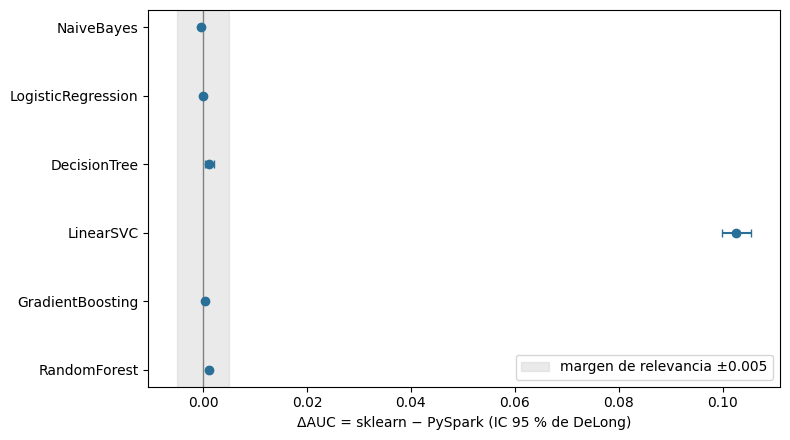

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
d = de_entornos
ax.errorbar(d['dAUC'], range(6), xerr=[d['dAUC'] - d['IC_inf'], d['IC_sup'] - d['dAUC']], fmt='o', color='#2a6f97', capsize=3)
ax.axvline(0, color='gray', lw=1); ax.axvspan(-MARGEN, MARGEN, color='#cccccc', alpha=0.4, label=f'margen de relevancia ±{MARGEN}')
ax.set_yticks(range(6)); ax.set_yticklabels(d['modelo']); ax.invert_yaxis()
ax.set_xlabel('ΔAUC = sklearn − PySpark (IC 95 % de DeLong)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(DIR_OUT + '/delong_entre_entornos.png', dpi=150); plt.show()

## 7. Cómo leer los resultados (para el informe)

- **Significativo ≠ relevante.** Con ~269 000 observaciones de prueba, DeLong detecta diferencias de AUC del orden de 0.001. Por eso se compara con un margen práctico (`|ΔAUC| ≥ 0.005`).
- **Entre entornos, mismo modelo.** Si el AUC coincide casi hasta el cuarto decimal, las diferencias vienen de detalles de implementación (mediana aproximada, `maxBins`, desviación muestral frente a poblacional, solver). Para `LinearSVC` la diferencia es de **pérdida** (`squared_hinge` en sklearn, `hinge` en Spark).
- **DeLong compara orden (AUC); McNemar compara decisiones con un umbral.** Pueden discrepar: dos modelos con el mismo AUC pueden tener umbrales muy distintos.
- **Limitaciones de DeLong:** asume AUC aproximadamente normales (válido con muestras grandes), compara solo AUC (no calibración ni costos), y trata la partición de prueba como fija: no incluye la variabilidad del entrenamiento ni de la búsqueda de hiperparámetros.
- **El bootstrap pareado** añade ΔAUC-PR (más sensible con clases desbalanceadas) y ΔF1, pero tampoco captura la variabilidad del entrenamiento.